In [2]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import umap.umap_ as umap
import seaborn as sns
import joblib
from gene_thesaurus import GeneThesaurus
from dotenv import load_dotenv

load_dotenv()

X_labeled_diagnostic_csv_path = os.getenv('X_TRAIN_CSV_PATH')
y_labeled_diagnostic_tsv_path = os.getenv('Y_TRAIN_TSV_PATH')
current_dir = os.getcwd()
color_palette_tsv_path = os.path.join(current_dir, '..', '..', 'reports', 'colors.tsv')
output_dir = os.getenv('OUTPUT_DIR')
n_jobs = int(os.getenv('N_JOBS', 1))
random_seed = int(os.getenv('RANDOM_SEED', 42))
selected_features_path = os.getenv('SELECTED_FEATURES_PATH') # os.path.join(output_dir, "selected_features.pkl")
rf_model_path = os.getenv('RF_MODEL_PATH')
N_TOP_FEATURES = 1000

print("Configuration:")
print(f"X_labeled_diagnostic_csv_path: {X_labeled_diagnostic_csv_path}")
print(f"y_labeled_diagnostic_tsv_path: {y_labeled_diagnostic_tsv_path}")
print(f"color_palette_tsv_path: {color_palette_tsv_path}")
print(f"output_dir: {output_dir}")
print(f"n_jobs: {n_jobs}")
print(f"random_seed: {random_seed}")
print(f"selected_features_path: {selected_features_path}")
print(f"rf_model_path: {rf_model_path}")
print(f"N_TOP_FEATURES: {N_TOP_FEATURES}")


Configuration:
X_labeled_diagnostic_csv_path: /home/mariya/Data/pallas/nf-core-gexml-output-krali-reprocessed/transpose/transposed.csv
y_labeled_diagnostic_tsv_path: /home/mariya/Data/pallas/nf-core-gexml-output-krali-reprocessed/class/subtypes.tsv
color_palette_tsv_path: /home/mariya/Development/pallas/training/gex/../../reports/colors.tsv
output_dir: /home/mariya/Data/pallas/training
n_jobs: 10
random_seed: 42
selected_features_path: /home/mariya/Data/pallas/models/gex.features.pkl
rf_model_path: /home/mariya/Data/pallas/models/gex.model.rf.pkl
N_TOP_FEATURES: 1000


In [3]:
# Load selected features
selected_features = joblib.load(selected_features_path)
selected_features

Index(['ENSG00000000938', 'ENSG00000001036', 'ENSG00000001497',
       'ENSG00000001561', 'ENSG00000001617', 'ENSG00000002586',
       'ENSG00000002587', 'ENSG00000002745', 'ENSG00000002746',
       'ENSG00000003096',
       ...
       'ENSG00000284690', 'ENSG00000284713', 'ENSG00000284730',
       'ENSG00000284770', 'ENSG00000286237', 'ENSG00000288649',
       'ENSG00000288701', 'ENSG00000288722', 'ENSG00000290292',
       'ENSG00000291237'],
      dtype='object', length=3934)

In [4]:
# Load model
rf_model = joblib.load(rf_model_path)
rf_model.feature_importances_

array([2.48034101e-05, 6.36834514e-04, 3.82250994e-05, ...,
       1.03272815e-05, 8.24700172e-05, 3.63837044e-06], shape=(3934,))

In [5]:
# Join selected features and feature importances
feature_importances = pd.DataFrame({
    "feature": selected_features,
    "importance": rf_model.feature_importances_
})
feature_importances_ranked = feature_importances.sort_values(by="importance", ascending=False)
feature_importances_ranked

# Translate feature names to gene symbols
# gt = GeneThesaurus(".")
# translated = gt.translate_genes(feature_importances_ranked["feature"].tolist(),
#                                source="ensembl_id", target="symbol")
# feature_importances_ranked["gene_symbol"] = feature_importances_ranked["feature"].map(translated)
# feature_importances_ranked

# Get top 100 features
top_features = feature_importances_ranked.head(N_TOP_FEATURES)
top_genes = top_features["feature"].tolist()
top_genes

['ENSG00000184507',
 'ENSG00000145794',
 'ENSG00000248329',
 'ENSG00000157985',
 'ENSG00000143995',
 'ENSG00000179241',
 'ENSG00000156298',
 'ENSG00000117519',
 'ENSG00000185630',
 'ENSG00000196208',
 'ENSG00000079102',
 'ENSG00000173482',
 'ENSG00000184185',
 'ENSG00000035720',
 'ENSG00000159217',
 'ENSG00000048052',
 'ENSG00000182670',
 'ENSG00000101115',
 'ENSG00000164330',
 'ENSG00000185046',
 'ENSG00000101230',
 'ENSG00000147364',
 'ENSG00000078399',
 'ENSG00000075420',
 'ENSG00000250366',
 'ENSG00000105642',
 'ENSG00000176595',
 'ENSG00000106278',
 'ENSG00000087495',
 'ENSG00000151729',
 'ENSG00000142188',
 'ENSG00000177455',
 'ENSG00000122025',
 'ENSG00000148655',
 'ENSG00000002745',
 'ENSG00000036448',
 'ENSG00000253293',
 'ENSG00000106665',
 'ENSG00000081189',
 'ENSG00000136213',
 'ENSG00000118946',
 'ENSG00000151502',
 'ENSG00000186187',
 'ENSG00000101197',
 'ENSG00000070759',
 'ENSG00000153208',
 'ENSG00000103449',
 'ENSG00000131686',
 'ENSG00000151474',
 'ENSG00000159147',


In [6]:

color_palette = pd.read_csv(color_palette_tsv_path, sep='\t', index_col=0, header=None).squeeze("columns").to_dict()
color_palette

# Add 'EXCLUDED: low HeH' to color palette
color_palette['EXCLUDED: low HeH'] = '#D3D3D3'
# Exclude b-other by making them light gray
color_palette['B-ALL, other'] = '#D3D3D3'


In [7]:
import pandas as pd
import numpy as np
from sklearn.manifold import TSNE
import hdbscan
from sklearn.preprocessing import OneHotEncoder

def create_tsne(X, y):
    reducer = TSNE(n_components=2,
                   perplexity=30,
                   learning_rate='auto',
                   init='pca',
                   random_state=random_seed)

    embedding_tsne = reducer.fit_transform(X)

    tsne_df = pd.DataFrame(embedding_tsne, columns=['tSNE1', 'tSNE2'], index=X.index)
    tsne_df['label'] = y.loc[tsne_df.index]
    return tsne_df

def show_tsne(tsne_df, title, palette, legend_title='Subtype'):
    # Plot t-SNE
    plt.figure(figsize=(10,10))
    sns.scatterplot(x='tSNE1',
                    y='tSNE2',
                    hue='label',
                    data=tsne_df,
                    palette=palette,
                    s=50,
                    alpha=0.8)

    plt.title(title, fontsize=18)
    plt.legend(
        title=legend_title,
        bbox_to_anchor=(1.05, 1),
        loc='upper left',
        borderaxespad=0,
        prop={'size': 8}
    )
    plt.tight_layout()
    plt.show()

# Create new col "disease" that sets B-ALL, T-ALL, AML or Non-leukemic
def map_disease(subtype):
    if "B-ALL" in subtype:
        return "B-ALL"
    elif "T-ALL" in subtype:
        return "T-ALL"
    elif "AML" in subtype:
        return "AML"
    else:
        return "Non-leukemic"

In [8]:
# Read in X and y
X_labeled_diagnostic = pd.read_csv(X_labeled_diagnostic_csv_path, index_col=0)
y_labeled_diagnostic = pd.read_csv(y_labeled_diagnostic_tsv_path, sep='\t', index_col=0)


In [9]:

y_labeled_diagnostic["class"].values

array(['B-ALL, high hyperdiploid', 'B-ALL, high hyperdiploid',
       'B-ALL, BCR::ABL1', 'B-ALL, iAMP21', 'B-ALL, ETV6::RUNX1', 'T-ALL',
       'B-ALL, iAMP21', 'T-ALL', 'B-ALL, high hyperdiploid',
       'B-ALL, high hyperdiploid', 'T-ALL', 'B-ALL, DUX4-r',
       'B-ALL, BCR::ABL1-like', 'B-ALL, high hyperdiploid', 'T-ALL',
       'B-ALL, ETV6::RUNX1', 'B-ALL, PAX5alt', 'B-ALL, high hyperdiploid',
       'B-ALL, BCR::ABL1', 'B-ALL, KMT2A-r', 'B-ALL, ZNF384-r', 'T-ALL',
       'B-ALL, high hyperdiploid', 'B-ALL, PAX5alt',
       'B-ALL, ETV6::RUNX1-like', 'B-ALL, PAX5alt', 'B-ALL, DUX4-r',
       'B-ALL, high hyperdiploid', 'B-ALL, ZNF384-r',
       'B-ALL, high hyperdiploid', 'B-ALL, high hyperdiploid', 'T-ALL',
       'T-ALL', 'B-ALL, other', 'B-ALL, KMT2A-r', 'B-ALL, other',
       'B-ALL, other', 'B-ALL, ETV6::RUNX1', 'B-ALL, PAX5alt',
       'B-ALL, KMT2A-r', 'B-ALL, high hyperdiploid', 'B-ALL, PAX5alt',
       'B-ALL, ZNF384-r', 'B-ALL, ZNF384-r', 'B-ALL, ETV6::RUNX1',
       '

In [10]:
# Get just selected features
X_labeled_diagnostic = X_labeled_diagnostic[top_genes]
X_labeled_diagnostic

,ENSG00000184507,ENSG00000145794,ENSG00000248329,ENSG00000157985,ENSG00000143995,ENSG00000179241,ENSG00000156298,ENSG00000117519,ENSG00000185630,ENSG00000196208,...,ENSG00000136379,ENSG00000170899,ENSG00000114745,ENSG00000008441,ENSG00000109501,ENSG00000178522,ENSG00000035403,ENSG00000163827,ENSG00000114541,ENSG00000179104
id,,,,,,,,,,,,,,,,,,,,,
ALL_1000,-0.825747,0.184460,3.899292,6.416855,-0.408652,4.256321,1.512733,6.725040,0.010097,-0.627216,...,7.159027,3.686725,2.828747,3.852405,6.403305,-0.825747,5.592560,4.926139,5.611169,1.421015
ALL_1001,-0.628463,-0.077272,-0.825747,-0.703839,-0.082169,-0.482287,4.922152,0.247861,-0.266357,-0.565318,...,1.656082,2.420209,4.871944,1.596697,1.272672,-0.825747,6.541600,1.278984,7.101190,0.394440
ALL_1003,-0.071755,-0.715199,-0.825747,-0.617990,-0.488620,-0.825747,0.740220,1.117687,-0.052781,-0.825747,...,0.170351,-0.400571,2.632231,6.105155,-0.825747,-0.825747,4.202698,2.815050,5.710354,0.319116
ALL_1005,-0.825747,0.201166,-0.825747,3.450455,-0.825747,-0.421046,-0.407656,-0.387581,-0.451834,-0.343194,...,3.872674,1.561256,3.516223,3.067295,0.123162,-0.825747,4.329850,2.390838,6.272367,-0.518521
ALL_1006,-0.825747,0.035924,-0.825747,3.486975,-0.766110,-0.687015,3.991451,1.584110,-0.638820,-0.673323,...,7.579602,3.750689,3.432214,3.697818,4.359432,-0.825747,5.200912,1.324492,7.883795,-0.673931
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ALL_984,-0.653854,-0.591664,-0.825747,0.855918,0.754137,-0.524620,4.838076,5.224036,1.276802,-0.765412,...,1.858345,1.185933,3.891397,6.760901,-0.710229,-0.825747,4.895495,1.635192,6.661821,-0.293135
ALL_985,-0.825747,-0.235386,-0.825747,2.884389,-0.295737,-0.825747,4.821413,7.269625,-0.263169,3.552032,...,1.360759,2.711320,3.931913,2.252398,5.879156,-0.825747,5.766914,1.608381,6.651352,-0.515035
ALL_986,-0.825747,-0.577146,-0.825747,3.339890,-0.683529,-0.369814,3.446821,-0.137798,-0.692150,-0.377127,...,5.307765,0.406221,5.395659,5.209425,3.531062,-0.825747,5.878796,3.294713,6.586745,-0.557552


In [11]:
# Remove samples with 'EXCLUDED: low HeH' label and "B-ALL, other" label
mask = ~y_labeled_diagnostic["class"].isin(['EXCLUDED: low HeH', 'B-ALL, other'])
X_labeled_diagnostic = X_labeled_diagnostic[mask]
y_labeled_diagnostic = y_labeled_diagnostic[mask]

/tmp/ipykernel_152773/3442894301.py:3: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  X_labeled_diagnostic = X_labeled_diagnostic[mask]


In [12]:
tsne_df = create_tsne(X_labeled_diagnostic, y_labeled_diagnostic)

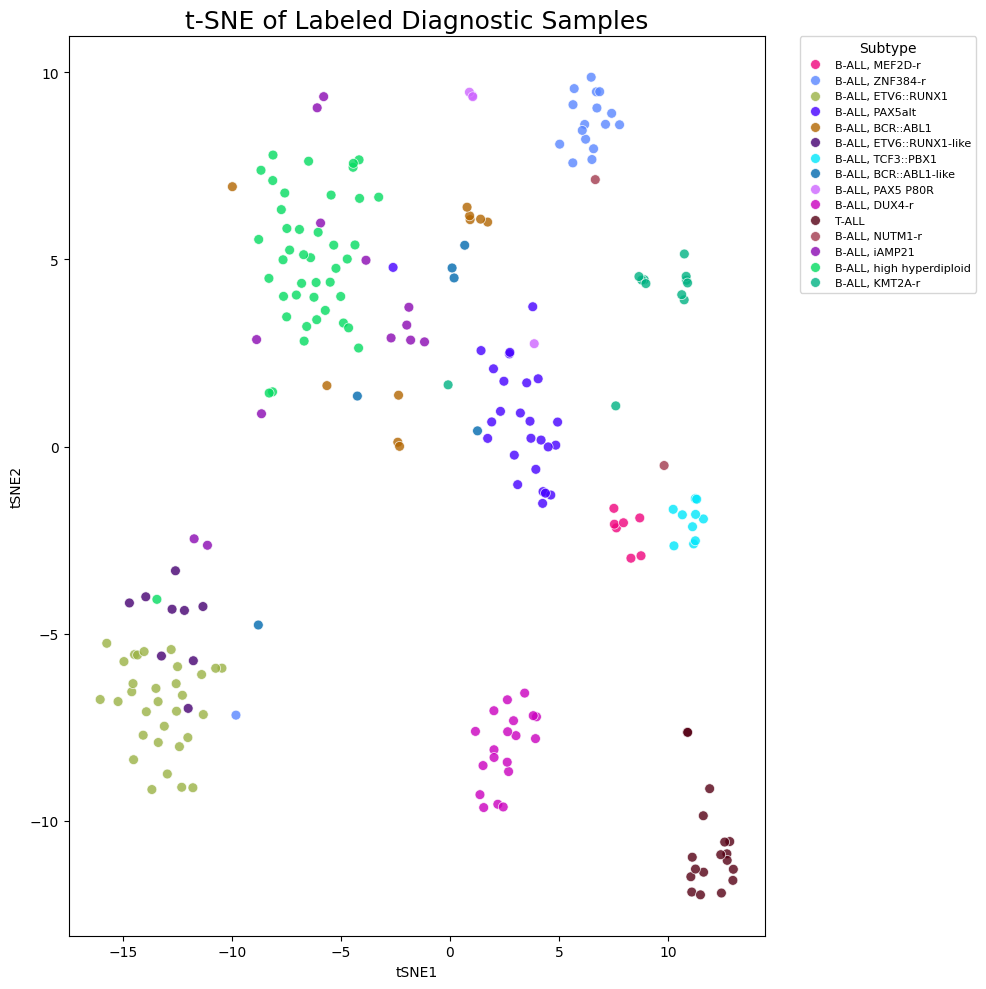

In [13]:
show_tsne(tsne_df, title='t-SNE of Labeled Diagnostic Samples', palette=color_palette, legend_title='Subtype')

In [14]:
print(", ".join(top_genes))

ENSG00000184507, ENSG00000145794, ENSG00000248329, ENSG00000157985, ENSG00000143995, ENSG00000179241, ENSG00000156298, ENSG00000117519, ENSG00000185630, ENSG00000196208, ENSG00000079102, ENSG00000173482, ENSG00000184185, ENSG00000035720, ENSG00000159217, ENSG00000048052, ENSG00000182670, ENSG00000101115, ENSG00000164330, ENSG00000185046, ENSG00000101230, ENSG00000147364, ENSG00000078399, ENSG00000075420, ENSG00000250366, ENSG00000105642, ENSG00000176595, ENSG00000106278, ENSG00000087495, ENSG00000151729, ENSG00000142188, ENSG00000177455, ENSG00000122025, ENSG00000148655, ENSG00000002745, ENSG00000036448, ENSG00000253293, ENSG00000106665, ENSG00000081189, ENSG00000136213, ENSG00000118946, ENSG00000151502, ENSG00000186187, ENSG00000101197, ENSG00000070759, ENSG00000153208, ENSG00000103449, ENSG00000131686, ENSG00000151474, ENSG00000159147, ENSG00000157680, ENSG00000005381, ENSG00000133392, ENSG00000120093, ENSG00000196632, ENSG00000183145, ENSG00000110811, ENSG00000176531, ENSG0000018591